# Två agenter i lagret

# Warehouse grid

Tecken i kartan:
* `.` golv
* `#` hylla
* `S` start
* `G` mål

Koordinater är (rad, kolumn), där (0, 0) är övre vänstra hörnet.

In [3]:
from collections import deque

import numpy as np

In [4]:
def make_layout(
    n_shelf_rows=2,
    shelves_per_row=3,
    shelf_width=2,
    shelf_depth=2,
):
    # en gång mer än antalet hyllor, åt båda hållen
    n_rows = n_shelf_rows * shelf_depth + (n_shelf_rows + 1)
    n_cols = shelves_per_row * shelf_width + (shelves_per_row + 1)

    # börja med golv överallt
    grid = np.full((n_rows, n_cols), ".")

    # lägg in hyllorna
    for i in range(n_shelf_rows):
        for j in range(shelves_per_row):
            top = 1 + i * (shelf_depth + 1)
            left = 1 + j * (shelf_width + 1)
            grid[top:top + shelf_depth, left:left + shelf_width] = "#"

    # start uppe till vänster, mål nere till höger
    grid[0, 0] = "S"
    grid[-1, -1] = "G"

    return "\n".join("".join(row) for row in grid)

In [5]:
class WarehouseGrid:
    def __init__(self, layout=None):
        # standardkartan om ingen annan skickas in
        if layout is None:
            layout = make_layout()

        rows = layout.strip().splitlines()
        self.n_rows = len(rows)
        self.n_cols = len(rows[0])

        # vilket tecken som står i varje cell
        symbols = {(r, c): symbol
                   for r, row in enumerate(rows)
                   for c, symbol in enumerate(row)}

        # sortera cellerna efter tecken
        self.shelf_cells = {cell for cell, s in symbols.items() if s == "#"}
        self.walkable_cells = {cell for cell, s in symbols.items() if s != "#"}
        self.start = next((cell for cell, s in symbols.items() if s == "S"), None)
        self.goal = next((cell for cell, s in symbols.items() if s == "G"), None)

        # plockplatser: golvcellerna bredvid varje hyllcell
        self.pick_spots = {
            shelf: self.walkable_neighbors(shelf) for shelf in self.shelf_cells
        }

        # vilken vara som ligger på vilken hylla
        self.item_to_shelf = {}

        self.check_all_cells_reachable()

    # golvcellerna ovanför, under, till vänster och till höger
    def walkable_neighbors(self, cell):
        r, c = cell
        around = [(r - 1, c), (r + 1, c), (r, c - 1), (r, c + 1)]
        return [n for n in around if n in self.walkable_cells]

    # felmeddelande om världen är uppdelad eller en hylla inte går att nå
    def check_all_cells_reachable(self):
        start = next(iter(self.walkable_cells))
        visited = {start}
        queue = deque([start])
        while queue:
            for n in self.walkable_neighbors(queue.popleft()):
                if n not in visited:
                    visited.add(n)
                    queue.append(n)

        # celler som aldrig nåddes betyder att världen är uppdelad
        if visited != self.walkable_cells:
            raise ValueError(f"Här kan du inte gå för fan! {sorted(self.walkable_cells - visited)}")

        # varje hylla måste ha minst en plockplats
        for shelf, spots in self.pick_spots.items():
            if not spots:
                raise ValueError(f"Hyllan {shelf} har ingen plockplats.")

    # lägg en vara på en hylla
    def add_item(self, item, shelf):
        if shelf not in self.shelf_cells:
            raise ValueError(f"{shelf} är ingen hylla!")
        self.item_to_shelf[item] = shelf

    # lägg varje vara på en slumpad hylla, max en vara per hylla
    def place_items_randomly(self, items, seed=None):
        rng = np.random.default_rng(seed)
        shelves = sorted(self.shelf_cells)
        chosen = rng.choice(len(shelves), size=len(items), replace=False)
        for item, i in zip(items, chosen):
            self.add_item(item, shelves[i])

    # var man ska stå för att plocka en vara
    def pick_spots_for_item(self, item):
        return self.pick_spots[self.item_to_shelf[item]]

    # rita världen, lager för lager
    def render(self, show_pick_spots=False):
        grid = np.full((self.n_rows, self.n_cols), ".")

        if show_pick_spots:
            for spots in self.pick_spots.values():
                for cell in spots:
                    grid[cell] = "p"

        for cell in self.shelf_cells:
            grid[cell] = "#"

        if self.start is not None:
            grid[self.start] = "S"
        if self.goal is not None:
            grid[self.goal] = "G"

        for row in grid:
            print(" ".join(row))
        print()

## Steg 1 och 2: två agenter som kan krocka

* Varje agent har en egen start och ett eget mål.
* `WAIT` = stå still, så att en agent kan släppa förbi den andra.
* Staten är båda agenternas positioner: `((rad, kol), (rad, kol))`.

Regler i `step()`:
1. Hylla eller utanför kartan -> agenten står kvar.
2. Båda vill till samma ruta -> båda står kvar.
3. De försöker byta plats -> båda står kvar.

Varje steg ger `-1`. Den som blir stoppad av den andra agenten får `-5` extra. En agent i mål står still.

Två sätt att räkna belöning (`reward_mode`):
* `"selfish"` (standard): en agent i mål får `0`. Varje agent bryr sig bara om sin egen tid.
* `"cooperative"`: en agent i mål får `-1` per steg tills *båda* är i mål. Den snabba agenten betalar alltså för att den långsamma inte är klar, så det lönar sig att släppa förbi.

In [6]:
STEP_REWARD = -1    # varje steg kostar, så agenterna vill bli klara snabbt
CRASH_REWARD = -5   # extra minus om man försöker gå in i den andra agenten

# hur varje handling flyttar en agent (rad, kolumn)
ACTIONS = {
    "UP": (-1, 0),
    "DOWN": (1, 0),
    "LEFT": (0, -1),
    "RIGHT": (0, 1),
    "WAIT": (0, 0),
}


class TwoAgentWarehouse:
    def __init__(self, grid, starts, goals, reward_mode="selfish"):
        self.grid = grid        # Jockes WarehouseGrid, hyllor och golv
        self.starts = starts    # en start per agent, t.ex. [(0, 0), (0, 9)]
        self.goals = goals      # ett mål per agent
        # "selfish": 0 när man själv är i mål. "cooperative": -1 tills båda är i mål
        if reward_mode not in ("selfish", "cooperative"):
            raise ValueError(f"Okänt reward_mode: {reward_mode}")
        self.reward_mode = reward_mode
        self.reset()

    # ställ båda agenterna på sin start igen
    def reset(self):
        self.positions = list(self.starts)
        return tuple(self.positions)

    # rita världen med agenterna A och B, och deras mål a och b
    def render(self):
        grid = np.full((self.grid.n_rows, self.grid.n_cols), ".")

        for cell in self.grid.shelf_cells:
            grid[cell] = "#"

        for goal, name in zip(self.goals, "ab"):
            grid[goal] = name
        for pos, name in zip(self.positions, "AB"):
            grid[pos] = name

        for row in grid:
            print(" ".join(row))
        print()

    # flytta en agent ett steg, stå kvar om det är hylla eller utanför kartan
    def move(self, pos, action):
        dr, dc = ACTIONS[action]
        new = (pos[0] + dr, pos[1] + dc)
        if new in self.grid.walkable_cells:
            return new
        return pos

    # båda agenterna tar en handling samtidigt, t.ex. actions = ("RIGHT", "WAIT")
    def step(self, actions):
        old = list(self.positions)

        # vart vill agenterna gå? en agent som redan är i mål står still
        wanted = []
        for i in range(2):
            if old[i] == self.goals[i]:
                wanted.append(old[i])
            else:
                wanted.append(self.move(old[i], actions[i]))

        # samma ruta eller byta plats med varandra -> båda står kvar
        same_cell = wanted[0] == wanted[1]
        swap = wanted[0] == old[1] and wanted[1] == old[0]
        if same_cell or swap:
            new = old
        else:
            new = wanted

        done = all(p == g for p, g in zip(new, self.goals))

        # rewards, en per agent
        rewards = []
        for i in range(2):
            if old[i] == self.goals[i]:
                if self.reward_mode == "selfish" or done:
                    rewards.append(0)  # redan klar, inget mer minus
                else:
                    rewards.append(STEP_REWARD)  # klar, men väntar på den andra
                continue
            reward = STEP_REWARD
            # ville gå men blev stoppad av den andra agenten
            if wanted[i] != old[i] and new[i] == old[i]:
                reward += CRASH_REWARD
            rewards.append(reward)

        self.positions = list(new)
        return tuple(self.positions), rewards, done


In [7]:
env = TwoAgentWarehouse(
    WarehouseGrid(),
    starts=[(0, 0), (0, 9)],
    goals=[(6, 9), (6, 0)],
)
print(env.reset())
env.render()


((0, 0), (0, 9))
A . . . . . . . . B
. # # . # # . # # .
. # # . # # . # # .
. . . . . . . . . .
. # # . # # . # # .
. # # . # # . # # .
b . . . . . . . . a



### Test av krockreglerna

In [8]:
# en smal korridor, så vi kan tvinga fram krockar
env = TwoAgentWarehouse(
    WarehouseGrid("....."),
    starts=[(0, 0), (0, 4)],
    goals=[(0, 4), (0, 0)],
)
env.render()

tests = [
    (("RIGHT", "LEFT"), "båda går ett steg"),
    (("RIGHT", "LEFT"), "båda vill till mitten -> krock"),
    (("RIGHT", "WAIT"), "B väntar, A går till mitten"),
    (("RIGHT", "LEFT"), "de försöker byta plats -> krock"),
    (("UP", "WAIT"), "A går in i väggen, står kvar men ingen krock"),
]
for actions, text in tests:
    state, rewards, done = env.step(actions)
    print(f"{actions}: {text}")
    print(f"rewards = {rewards}")
    env.render()


A . . . B

('RIGHT', 'LEFT'): båda går ett steg
rewards = [-1, -1]
b A . B a

('RIGHT', 'LEFT'): båda vill till mitten -> krock
rewards = [-6, -6]
b A . B a

('RIGHT', 'WAIT'): B väntar, A går till mitten
rewards = [-1, -1]
b . A B a

('RIGHT', 'LEFT'): de försöker byta plats -> krock
rewards = [-6, -6]
b . A B a

('UP', 'WAIT'): A går in i väggen, står kvar men ingen krock
rewards = [-1, -1]
b . A B a



## Steg 3: agenterna lär sig med Q-learning

* Varje agent har en egen Q-tabell (oberoende Q-learning).
* Staten är båda positionerna, så varje agent vet var den andra står.
* Epsilon-greedy: oftast bästa handlingen, ibland en slumpad för att utforska.
* Uppdatering: `Q[s][a] += alpha * (r + gamma * max Q[s'] - Q[s][a])`
* En agent som redan står i mål lär sig också, fast den inte kan röra sig. I `cooperative`-läget får den ju fortfarande minus, och det måste synas i Q-värdena för stegen innan. I `selfish`-läget är belöningen 0 i mål, så där ändras ingenting.

In [9]:
from collections import defaultdict

ACTION_NAMES = list(ACTIONS)  # ["UP", "DOWN", "LEFT", "RIGHT", "WAIT"]


# välj handling: oftast den bästa, ibland en slumpad (epsilon-greedy)
def choose_action(Q, state, epsilon, rng):
    if rng.random() < epsilon:
        return rng.integers(len(ACTION_NAMES))
    q = Q[state]
    best = np.flatnonzero(q == q.max())  # om flera är lika bra, slumpa bland dem
    return rng.choice(best)


# varje agent har en egen Q-tabell, men ser båda positionerna
def train(env, episodes=10000, alpha=0.5, gamma=0.99, epsilon=0.1, max_steps=200, seed=0):
    rng = np.random.default_rng(seed)
    Qs = [defaultdict(lambda: np.zeros(len(ACTION_NAMES))) for _ in range(2)]
    steps_per_episode = []

    for episode in range(episodes):
        state = env.reset()
        for t in range(max_steps):
            a = [choose_action(Qs[i], state, epsilon, rng) for i in range(2)]
            next_state, rewards, done = env.step((ACTION_NAMES[a[0]], ACTION_NAMES[a[1]]))

            for i in range(2):
                if done:
                    target = rewards[i]  # episoden slut, ingen framtid kvar
                else:
                    target = rewards[i] + gamma * Qs[i][next_state].max()
                Qs[i][state][a[i]] += alpha * (target - Qs[i][state][a[i]])

            state = next_state
            if done:
                break
        steps_per_episode.append(t + 1)

    return Qs, steps_per_episode


In [10]:
# kör en episod utan slump och visa vad agenterna lärt sig
def run_greedy(env, Qs, max_steps=50, show=True):
    rng = np.random.default_rng(0)
    state = env.reset()
    finished = [None, None]  # vilket steg varje agent kom i mål
    crashes = 0
    if show:
        env.render()

    for t in range(1, max_steps + 1):
        a = [choose_action(Qs[i], state, 0.0, rng) for i in range(2)]
        state, rewards, done = env.step((ACTION_NAMES[a[0]], ACTION_NAMES[a[1]]))
        crashes += sum(r < STEP_REWARD for r in rewards)
        for i in range(2):
            if finished[i] is None and state[i] == env.goals[i]:
                finished[i] = t
        if show:
            print(f"steg {t}: A {ACTION_NAMES[a[0]]}, B {ACTION_NAMES[a[1]]}")
            env.render()
        if done:
            break

    print(f"A i mål efter {finished[0]} steg, B efter {finished[1]} steg, {crashes} krockar")


In [11]:
env = TwoAgentWarehouse(
    WarehouseGrid(),
    starts=[(0, 0), (0, 9)],
    goals=[(6, 9), (6, 0)],
)
Qs, steps = train(env)

# medel antal steg per 1000 episoder, ska gå ner när de lär sig
for i in range(0, len(steps), 1000):
    print(f"episod {i:4d}-{i + 999}: {np.mean(steps[i:i + 1000]):6.1f} steg")


episod    0-999:  105.4 steg
episod 1000-1999:   48.6 steg
episod 2000-2999:   35.1 steg
episod 3000-3999:   29.3 steg
episod 4000-4999:   27.0 steg
episod 5000-5999:   24.2 steg
episod 6000-6999:   23.0 steg
episod 7000-7999:   20.9 steg
episod 8000-8999:   19.6 steg
episod 9000-9999:   19.7 steg


In [12]:
run_greedy(env, Qs)

A . . . . . . . . B
. # # . # # . # # .
. # # . # # . # # .
. . . . . . . . . .
. # # . # # . # # .
. # # . # # . # # .
b . . . . . . . . a

steg 1: A DOWN, B LEFT
. . . . . . . . B .
A # # . # # . # # .
. # # . # # . # # .
. . . . . . . . . .
. # # . # # . # # .
. # # . # # . # # .
b . . . . . . . . a

steg 2: A DOWN, B LEFT
. . . . . . . B . .
. # # . # # . # # .
A # # . # # . # # .
. . . . . . . . . .
. # # . # # . # # .
. # # . # # . # # .
b . . . . . . . . a

steg 3: A DOWN, B LEFT
. . . . . . B . . .
. # # . # # . # # .
. # # . # # . # # .
A . . . . . . . . .
. # # . # # . # # .
. # # . # # . # # .
b . . . . . . . . a

steg 4: A DOWN, B LEFT
. . . . . B . . . .
. # # . # # . # # .
. # # . # # . # # .
. . . . . . . . . .
A # # . # # . # # .
. # # . # # . # # .
b . . . . . . . . a

steg 5: A DOWN, B LEFT
. . . . B . . . . .
. # # . # # . # # .
. # # . # # . # # .
. . . . . . . . . .
. # # . # # . # # .
A # # . # # . # # .
b . . . . . . . . a

steg 6: A DOWN, B LEFT
. . . B . . . . 

## Steg 4: trång karta

En korridor med en enda ficka i mitten. Agenterna måste mötas, så en av dem måste väja in i fickan och vänta.

Bästa möjliga: den ena går raka vägen på 8 steg plus lite väntan, den andra väjer. Totalt 10 + 9 steg.

In [13]:
# en korridor med en enda ficka i mitten där man kan väja
narrow = TwoAgentWarehouse(
    WarehouseGrid("""
####.####
.........
"""),
    starts=[(1, 0), (1, 8)],
    goals=[(1, 8), (1, 0)],
)
narrow_Qs, narrow_steps = train(narrow)
run_greedy(narrow, narrow_Qs)


# # # # . # # # #
A . . . . . . . B

steg 1: A RIGHT, B UP
# # # # . # # # #
b A . . . . . . B

steg 2: A RIGHT, B UP
# # # # . # # # #
b . A . . . . . B

steg 3: A RIGHT, B LEFT
# # # # . # # # #
b . . A . . . B a

steg 4: A RIGHT, B WAIT
# # # # . # # # #
b . . . A . . B a

steg 5: A DOWN, B LEFT
# # # # . # # # #
b . . . A . B . a

steg 6: A UP, B WAIT
# # # # A # # # #
b . . . . . B . a

steg 7: A RIGHT, B LEFT
# # # # A # # # #
b . . . . B . . a

steg 8: A WAIT, B LEFT
# # # # A # # # #
b . . . B . . . a

steg 9: A WAIT, B LEFT
# # # # A # # # #
b . . B . . . . a

steg 10: A WAIT, B LEFT
# # # # A # # # #
b . B . . . . . a

steg 11: A DOWN, B LEFT
# # # # . # # # #
b B . . A . . . a

steg 12: A RIGHT, B LEFT
# # # # . # # # #
B . . . . A . . a

steg 13: A RIGHT, B LEFT
# # # # . # # # #
B . . . . . A . a

steg 14: A RIGHT, B WAIT
# # # # . # # # #
B . . . . . . A a

steg 15: A RIGHT, B RIGHT
# # # # . # # # #
B . . . . . . . A

A i mål efter 15 steg, B efter 12 steg, 0 krockar


Resultatet varierar beroende på seed. Båda lär sig alltid att undvika krockar, men inte alltid den kortaste vägen. Det beror på att varje agent lär sig medan den andra också lär sig och ändrar beteende, så världen ser inte likadan ut från en episod till nästa.

In [14]:
# samma karta med olika inställningar och seeds, bästa möjliga är 10 och 9 steg
for settings in [{}, {"seed": 1}, {"seed": 2}, {"episodes": 50000, "alpha": 0.2}]:
    test_Qs, _ = train(narrow, **settings)
    print(f"{str(settings):35}", end="")
    run_greedy(narrow, test_Qs, show=False)


{}                                 A i mål efter 15 steg, B efter 12 steg, 0 krockar
{'seed': 1}                        A i mål efter 12 steg, B efter 10 steg, 0 krockar
{'seed': 2}                        A i mål efter 13 steg, B efter 10 steg, 0 krockar
{'episodes': 50000, 'alpha': 0.2}  A i mål efter 9 steg, B efter 10 steg, 0 krockar


## Steg 5: n-stegs Q-learning

Vanlig Q-learning uppdaterar efter ett steg och lånar resten från `max Q[s']`. Här väntar vi `n` steg och summerar de `n` riktiga belöningarna innan vi lånar:

`G = r_0 + gamma * r_1 + ... + gamma^(n-1) * r_(n-1) + gamma^n * max Q[s_n]`

`Q[s_0][a_0] += alpha * (G - Q[s_0][a_0])`

* Belöningen från en krock (`-5`) når då tillbaka till handlingen som orsakade den, inte bara till den sista.
* Varje agent har sin egen buffert med sina senaste `n` steg (oberoende Q-learning, som förut).
* När en agent kommer i mål finns ingen framtid att låna från, så de sista stegen uppdateras med de riktiga belöningarna.
* Tar episoden slut på tidsgränsen (`max_steps`) är det inte ett riktigt slut, så då lånar vi från `max Q` i sista staten.
* `n = 1` är exakt samma sak som `train()` ovan.

Källa: Sutton & Barto, *Reinforcement Learning: An Introduction* (2:a upplagan, 2018), kapitel 7 (n-step Sarsa, avsnitt 7.2). Vi byter ut Sarsa-lånet `Q[s_n][a_n]` mot `max Q[s_n]`, som i n-step Q-learning i Mnih et al. (2016), *Asynchronous Methods for Deep Reinforcement Learning*, ICML.

Obs: med epsilon-greedy följer de `n` belöningarna beteendepolicyn, inte den giriga policyn, så det är strikt sett inte on-policy-korrekt. Det brukar fungera bra i små världar, men tänk på det om resultaten ser konstiga ut.

In [15]:
# uppdatera den äldsta posten i bufferten med en n-stegs retur
# buffer = [(state, action, reward), ...] med äldsta först
# bootstrap_state = staten att låna värde från, eller None om agenten är i mål
def nstep_update(Q, buffer, bootstrap_state, alpha, gamma):
    G = 0.0
    if bootstrap_state is not None:
        G = Q[bootstrap_state].max()
    # räkna bakifrån: G = r + gamma * G, så gamma^len hamnar på lånet
    for _, _, r in reversed(buffer):
        G = r + gamma * G
    s, a, _ = buffer[0]
    Q[s][a] += alpha * (G - Q[s][a])


# samma som train(), men med n-stegs retur. n=1 ger samma resultat som train()
def train_nstep(env, n=5, episodes=10000, alpha=0.5, gamma=0.99, epsilon=0.1, max_steps=200, seed=0):
    rng = np.random.default_rng(seed)
    Qs = [defaultdict(lambda: np.zeros(len(ACTION_NAMES))) for _ in range(2)]
    steps_per_episode = []

    for episode in range(episodes):
        state = env.reset()
        buffers = [[], []]  # varje agents senaste (state, action, reward)

        for t in range(max_steps):
            a = [choose_action(Qs[i], state, epsilon, rng) for i in range(2)]
            next_state, rewards, done = env.step((ACTION_NAMES[a[0]], ACTION_NAMES[a[1]]))

            for i in range(2):
                buffers[i].append((state, a[i], rewards[i]))

                if done:
                    # episoden slut: uppdatera alla kvarvarande steg utan att låna
                    while buffers[i]:
                        nstep_update(Qs[i], buffers[i], None, alpha, gamma)
                        buffers[i].pop(0)
                elif len(buffers[i]) == n:
                    # bufferten full: uppdatera äldsta steget och släpp det
                    nstep_update(Qs[i], buffers[i], next_state, alpha, gamma)
                    buffers[i].pop(0)

            state = next_state
            if done:
                break

        # tidsgränsen nåddes: lån från sista staten för det som är kvar
        for i in range(2):
            while buffers[i]:
                nstep_update(Qs[i], buffers[i], state, alpha, gamma)
                buffers[i].pop(0)

        steps_per_episode.append(t + 1)

    return Qs, steps_per_episode

### Test: n=1 ska ge exakt samma som `train()`

In [16]:
env = TwoAgentWarehouse(
    WarehouseGrid(),
    starts=[(0, 0), (0, 9)],
    goals=[(6, 9), (6, 0)],
)
_, steps_1step = train(env, episodes=2000, seed=0)
_, steps_n1 = train_nstep(env, n=1, episodes=2000, seed=0)
print("samma stegkurva:", steps_1step == steps_n1)

samma stegkurva: True


### Jämförelse: olika n på den trånga kartan

Bästa möjliga är 10 steg tills båda är i mål (kontrollerat med bredden-först-sökning över alla gemensamma tillstånd). Vi tränar flera seeds per `n` och tittar på den giriga policyn efteråt: hur många seeds som hittar bästa möjliga, och hur många krockar det blir.

In [17]:
# kör en girig episod tyst och returnera (steg tills båda i mål, antal krockar)
def greedy_result(env, Qs, max_steps=50):
    rng = np.random.default_rng(0)
    state = env.reset()
    crashes = 0
    for t in range(1, max_steps + 1):
        a = [choose_action(Qs[i], state, 0.0, rng) for i in range(2)]
        state, rewards, done = env.step((ACTION_NAMES[a[0]], ACTION_NAMES[a[1]]))
        crashes += sum(r < STEP_REWARD for r in rewards)
        if done:
            return t, crashes
    return None, crashes  # kom inte i mål


seeds = range(5)  # tar några minuter, öka för stabilare siffror
for n in [1, 3, 5, 10]:
    results = []
    for seed in seeds:
        Qs_n, _ = train_nstep(narrow, n=n, episodes=10000, seed=seed)
        results.append(greedy_result(narrow, Qs_n))
    finished = [t for t, _ in results if t is not None]
    # optimum: den som väjer är klar efter 10 steg, den andra efter 9 -> båda klara efter 10
    optimal = sum(t == 10 for t in finished)
    print(f"n={n:2d}: {len(finished)}/{len(seeds)} klarar det, {optimal}/{len(seeds)} optimala, "
          f"medel {np.mean(finished) if finished else float('nan'):.1f} steg, "
          f"{sum(c for _, c in results)} krockar totalt")

n= 1: 5/5 klarar det, 0/5 optimala, medel 13.4 steg, 0 krockar totalt
n= 3: 2/5 klarar det, 0/5 optimala, medel 14.5 steg, 0 krockar totalt
n= 5: 4/5 klarar det, 0/5 optimala, medel 14.5 steg, 0 krockar totalt
n=10: 2/5 klarar det, 0/5 optimala, medel 16.5 steg, 0 krockar totalt


## Steg 5b: självisk eller hänsynsfull belöning

Samma trånga karta, men vi jämför de två sätten att räkna belöning:

* `selfish`: varje agent får minus tills den själv är i mål.
* `cooperative`: båda får minus tills den sista är i mål (Filips idé).

Det vi vill se: i `cooperative` ska den snabba agenten inte tjäna något på att tränga sig, för den väntar ändå på den andra. Blir det färre krockar och kortare tid tills båda är klara?

Vi tränar flera seeds per läge med vanlig Q-learning (`n=1`, det som gick bäst ovan) och mäter på den giriga policyn: när varje agent kom i mål, tid tills båda var klara, och antal krockar.

In [18]:
# kör en girig episod tyst: (steg när A kom i mål, steg när B kom i mål, krockar)
def greedy_finish_times(env, Qs, max_steps=50):
    rng = np.random.default_rng(0)
    state = env.reset()
    finished = [None, None]
    crashes = 0
    for t in range(1, max_steps + 1):
        a = [choose_action(Qs[i], state, 0.0, rng) for i in range(2)]
        state, rewards, done = env.step((ACTION_NAMES[a[0]], ACTION_NAMES[a[1]]))
        crashes += sum(r < STEP_REWARD for r in rewards)
        for i in range(2):
            if finished[i] is None and state[i] == env.goals[i]:
                finished[i] = t
        if done:
            break
    return finished[0], finished[1], crashes


narrow_layout = """
####.####
.........
"""
seeds = range(10)
for mode in ["selfish", "cooperative"]:
    env_mode = TwoAgentWarehouse(
        WarehouseGrid(narrow_layout),
        starts=[(1, 0), (1, 8)],
        goals=[(1, 8), (1, 0)],
        reward_mode=mode,
    )
    results = [greedy_finish_times(env_mode, train(env_mode, seed=seed)[0]) for seed in seeds]
    both_done = [max(a, b) for a, b, _ in results if a is not None and b is not None]
    print(f"{mode:12s}: {len(both_done)}/{len(seeds)} klarar det, "
          f"{sum(t == 10 for t in both_done)}/{len(seeds)} optimala (10 steg), "
          f"medel {np.mean(both_done) if both_done else float('nan'):.1f} steg tills båda klara, "
          f"{sum(c for _, _, c in results)} krockar totalt")
    for seed, (a, b, c) in zip(seeds, results):
        print(f"    seed {seed}: A {a}, B {b}, krockar {c}")


selfish     : 9/10 klarar det, 0/10 optimala (10 steg), medel 12.9 steg tills båda klara, 0 krockar totalt
    seed 0: A 15, B 12, krockar 0
    seed 1: A 12, B 10, krockar 0
    seed 2: A 13, B 10, krockar 0
    seed 3: A 13, B 11, krockar 0
    seed 4: A 11, B 14, krockar 0
    seed 5: A 11, B 14, krockar 0
    seed 6: A 11, B 10, krockar 0
    seed 7: A 11, B 13, krockar 0
    seed 8: A 11, B 10, krockar 0
    seed 9: A None, B None, krockar 0
cooperative : 9/10 klarar det, 1/10 optimala (10 steg), medel 12.2 steg tills båda klara, 0 krockar totalt
    seed 0: A 11, B 11, krockar 0
    seed 1: A 12, B 13, krockar 0
    seed 2: A None, B None, krockar 0
    seed 3: A 10, B 10, krockar 0
    seed 4: A 13, B 13, krockar 0
    seed 5: A 10, B 12, krockar 0
    seed 6: A 14, B 13, krockar 0
    seed 7: A 12, B 13, krockar 0
    seed 8: A 11, B 11, krockar 0
    seed 9: A 13, B 13, krockar 0


## Steg 6: plocka en vara i taget och leverera

Agenten plockar en vara, bär den till lämningsplatsen `D` (nere i mitten) och hämtar sedan nästa.

* Staten är `(position, mask, carrying)`. `mask` har bit `i` satt när vara `i` har lämnat hyllan (plockad eller levererad). `carrying` är `True` när agenten bär på en vara. Levererade varor är alltså de i `mask` som inte bärs just nu.
* `PICK` plockar varan om agenten står på en plockplats (golvrutan bredvid hyllan) och inte redan bär på något.
* Leveransen sker automatiskt när agenten bär en vara och kliver på `D`. Vill man ha en egen `DROP`-handling går det att lägga till.
* Belöning: `-1` per steg, `+5` för en plockad vara, `+10` för en levererad vara.
* Straff: `-2` extra om man försöker `PICK` där det inte finns någon vara, eller medan man redan bär en.
* Episoden är slut när sista varan är levererad. Skickar man in `finish=(rad, kol)` måste agenten dessutom stå där (t.ex. laddstationen).

`transition()` ändrar ingenting utan bara räknar ut vad som skulle hända, så samma regler används av `step()` och av sökningen som räknar ut bästa möjliga lösning.

In [19]:
PICK_REWARD = 5          # plockar en vara
DELIVER_REWARD = 10      # lämnar en vara på D
BAD_PICK_PENALTY = -2    # extra straff: PICK utan vara i närheten, eller när man redan bär en

# de gamla handlingarna plus PICK
ACTIONS_PICK = list(ACTIONS) + ["PICK"]   # UP, DOWN, LEFT, RIGHT, WAIT, PICK


class PickupWarehouse:
    def __init__(self, grid, items, start=None, dropoff=None, finish=None):
        self.grid = grid                # WarehouseGrid med varorna utplacerade
        self.items = list(items)        # t.ex. [0, 1, 2], plats i listan = bit i masken
        self.start = grid.start if start is None else start
        # lämningsplats: nedre mitten om inget annat anges
        self.dropoff = (grid.n_rows - 1, grid.n_cols // 2) if dropoff is None else dropoff
        self.finish = finish            # None = klart direkt när sista varan är levererad
        self.full_mask = (1 << len(self.items)) - 1

        for item in self.items:
            if item not in grid.item_to_shelf:
                raise ValueError(f"Vara {item} ligger inte på någon hylla.")
        if self.dropoff not in grid.walkable_cells:
            raise ValueError(f"Lämningsplatsen {self.dropoff} är inte en golvruta.")
        self.reset()

    def reset(self):
        self.pos = self.start
        self.mask = 0              # varor som lämnat hyllan
        self.carrying = False      # bär agenten på en vara?
        return (self.pos, self.mask, self.carrying)

    # räkna ut vad en handling gör, utan att ändra något
    def transition(self, pos, mask, carrying, action):
        reward = STEP_REWARD
        if action == "PICK":
            picked = False
            if not carrying:
                for i, item in enumerate(self.items):
                    already_gone = mask & (1 << i)
                    if not already_gone and pos in self.grid.pick_spots_for_item(item):
                        mask |= 1 << i
                        carrying = True
                        picked = True
                        reward += PICK_REWARD
                        break      # en vara per PICK
            if not picked:
                reward += BAD_PICK_PENALTY   # ingen vara här, eller händerna är fulla
        else:
            dr, dc = ACTIONS[action]
            new = (pos[0] + dr, pos[1] + dc)
            if new in self.grid.walkable_cells:   # hylla eller utanför -> står kvar
                pos = new
            if carrying and pos == self.dropoff:  # leverera automatiskt
                carrying = False
                reward += DELIVER_REWARD

        all_delivered = mask == self.full_mask and not carrying
        done = all_delivered and (self.finish is None or pos == self.finish)
        return pos, mask, carrying, reward, done

    def step(self, action):
        self.pos, self.mask, self.carrying, reward, done = self.transition(
            self.pos, self.mask, self.carrying, action)
        return (self.pos, self.mask, self.carrying), reward, done

    def n_delivered(self):
        return bin(self.mask).count("1") - int(self.carrying)

    # rita världen: S = start, D = lämningsplats, A = agenten (C när den bär en vara),
    # siffra = vara kvar på hyllan, x = vara som lämnat hyllan
    def render(self):
        grid = np.full((self.grid.n_rows, self.grid.n_cols), ".")
        for cell in self.grid.shelf_cells:
            grid[cell] = "#"
        for i, item in enumerate(self.items):
            shelf = self.grid.item_to_shelf[item]
            grid[shelf] = "x" if self.mask & (1 << i) else str(item)
        grid[self.start] = "S"
        grid[self.dropoff] = "D"
        grid[self.pos] = "C" if self.carrying else "A"
        for row in grid:
            print(" ".join(row))
        print()


# minsta antal steg för att leverera allt (bredden-först över alla (position, mask, carrying),
# samma regler som step)
def optimal_steps(env):
    first = (env.start, 0, False)
    seen = {first}
    queue = deque([(first, 0)])
    while queue:
        (pos, mask, carrying), d = queue.popleft()
        for action in ACTIONS_PICK:
            new_pos, new_mask, new_carrying, _, done = env.transition(pos, mask, carrying, action)
            if done:
                return d + 1
            nxt = (new_pos, new_mask, new_carrying)
            if nxt not in seen:
                seen.add(nxt)
                queue.append((nxt, d + 1))
    return None

### Träning

Samma n-stegs Q-learning som i steg 5 (`nstep_update` återanvänds), men för en agent. `n=1` är vanlig Q-learning.

Med `n=5` behövs ett lågt `alpha` (0.1). De fem belöningarna innehåller slumpade epsilon-steg, och med `alpha=0.5` blir uppdateringarna så brusiga att agenten ofta fastnar.

In [20]:
# som choose_action, men slumpar bland alla handlingar inklusive PICK
def choose_action_pick(Q, state, epsilon, rng):
    if rng.random() < epsilon:
        return rng.integers(len(ACTIONS_PICK))
    q = Q[state]
    best = np.flatnonzero(q == q.max())
    return rng.choice(best)


def train_pickup(env, n=1, episodes=3000, alpha=0.5, gamma=0.99, epsilon=0.1, max_steps=300, seed=0):
    rng = np.random.default_rng(seed)
    Q = defaultdict(lambda: np.zeros(len(ACTIONS_PICK)))
    steps_per_episode = []

    for episode in range(episodes):
        state = env.reset()
        buffer = []

        for t in range(max_steps):
            a = choose_action_pick(Q, state, epsilon, rng)
            next_state, reward, done = env.step(ACTIONS_PICK[a])
            buffer.append((state, a, reward))

            if done:
                # klar: uppdatera allt som är kvar utan att låna
                while buffer:
                    nstep_update(Q, buffer, None, alpha, gamma)
                    buffer.pop(0)
                break
            if len(buffer) == n:
                nstep_update(Q, buffer, next_state, alpha, gamma)
                buffer.pop(0)
            state = next_state

        # tidsgränsen nåddes: lån från sista staten
        while buffer:
            nstep_update(Q, buffer, state, alpha, gamma)
            buffer.pop(0)

        steps_per_episode.append(t + 1)

    return Q, steps_per_episode


# kör en girig episod och skriv ut vad agenten gör
def run_greedy_pickup(env, Q, max_steps=150, show=True):
    rng = np.random.default_rng(0)
    state = env.reset()
    if show:
        env.render()
    bad_picks = 0
    for t in range(1, max_steps + 1):
        a = choose_action_pick(Q, state, 0.0, rng)
        picked_before, delivered_before = bin(env.mask).count("1"), env.n_delivered()
        state, reward, done = env.step(ACTIONS_PICK[a])
        note = ""
        if bin(env.mask).count("1") > picked_before:
            note = "  <- plockade en vara"
        elif env.n_delivered() > delivered_before:
            note = "  <- levererade"
        elif ACTIONS_PICK[a] == "PICK":
            note = "  <- onödig PICK (straff)"
            bad_picks += 1
        if show:
            print(f"steg {t:2d}: {ACTIONS_PICK[a]:5s} -> {state[0]}{note}")
        if done:
            break
    if show:
        print()
        env.render()
    return (t if done else None), env.n_delivered(), bad_picks

### Test: en agent, 9x9, tre varor

Kartan är 9x9 med fyra rader enradiga hyllor. Tre varor läggs på slumpade hyllor (`seed=1`). Agenten startar uppe till vänster, plockar en vara i taget och lämnar den vid `D` (nere i mitten). Bästa möjliga räknas ut exakt för att jämföra med.

In [21]:
# 9x9: 4 hyllrader med djup 1, 2 hyllor per rad med bredd 3
layout = make_layout(n_shelf_rows=4, shelves_per_row=2, shelf_width=3, shelf_depth=1)
grid = WarehouseGrid(layout)
grid.place_items_randomly([0, 1, 2], seed=1)
env = PickupWarehouse(grid, items=[0, 1, 2], finish=(0,0))   # lämningsplats: nedre mitten
print(f"storlek {grid.n_rows}x{grid.n_cols}, varor på hyllorna: {grid.item_to_shelf}, lämningsplats: {env.dropoff}")
env.render()

best = optimal_steps(env)
print(f"bästa möjliga: {best} steg\n")

Q, steps = train_pickup(env, n=5, alpha=0.1, episodes=5000, seed=0)
for i in range(0, len(steps), 1000):
    print(f"episod {i:4d}-{i + 999}: {np.mean(steps[i:i + 1000]):6.1f} steg")
print()

finished, delivered, bad_picks = run_greedy_pickup(env, Q)
print(f"giriga policyn: {finished} steg (bäst {best}), {delivered} varor levererade, {bad_picks} onödiga PICK")

storlek 9x9, varor på hyllorna: {0: (3, 7), 1: (3, 6), 2: (7, 1)}, lämningsplats: (8, 4)
A . . . . . . . .
. # # # . # # # .
. . . . . . . . .
. # # # . # 1 0 .
. . . . . . . . .
. # # # . # # # .
. . . . . . . . .
. 2 # # . # # # .
. . . . D . . . .

bästa möjliga: 51 steg

episod    0-999:  155.6 steg
episod 1000-1999:   58.4 steg
episod 2000-2999:   58.6 steg
episod 3000-3999:   57.6 steg
episod 4000-4999:   59.3 steg

A . . . . . . . .
. # # # . # # # .
. . . . . . . . .
. # # # . # 1 0 .
. . . . . . . . .
. # # # . # # # .
. . . . . . . . .
. 2 # # . # # # .
. . . . D . . . .

steg  1: RIGHT -> (0, 1)
steg  2: RIGHT -> (0, 2)
steg  3: RIGHT -> (0, 3)
steg  4: RIGHT -> (0, 4)
steg  5: DOWN  -> (1, 4)
steg  6: DOWN  -> (2, 4)
steg  7: DOWN  -> (3, 4)
steg  8: DOWN  -> (4, 4)
steg  9: RIGHT -> (4, 5)
steg 10: RIGHT -> (4, 6)
steg 11: RIGHT -> (4, 7)
steg 12: PICK  -> (4, 7)  <- plockade en vara
steg 13: LEFT  -> (4, 6)
steg 14: LEFT  -> (4, 5)
steg 15: LEFT  -> (4, 4)
steg 16: DOWN  

## Steg 7: två agenter som plockar i samma lager

Nu sätter vi ihop steg 2 (krockregler) och steg 6 (plockning). Som riktiga plockrobotar har varje agent sina egna varor, men de delar lager och lämningsplats `D`, så de kan vara i vägen för varandra.

* Varje agent har en egen lista med varor, en egen start som också är mål, och de delar `D`.
* Det agent `i` ser (`obs(i)`): sin egen position, sin mask, om den bär något, och var den andra står. Inte den andras varor, annars blir Q-tabellen för stor.
* Krockreglerna är samma som i steg 2, även vid `D`. `PICK` flyttar inte agenten, så den kan inte krocka.
* Belöningar: samma som i steg 6 (`-1` per steg, `+5` plock, `+10` leverans, `-2` onödig `PICK`) plus `-5` för krock. En agent är klar när allt är levererat och den står på sin start igen. `reward_mode` som i steg 5b: `selfish` ger `0` när man är klar, `cooperative` ger `-1` tills båda är klara.

Bästa möjliga för två agenter är dyrt att räkna ut exakt (alla kombinationer av båda tillstånden), så vi använder en undre gräns: varje agent ensam i lagret med sina varor, räknat med `optimal_steps` från steg 6. Ingen kan bli snabbare än så, och skillnaden mot den gränsen är priset för att dela lager.

In [22]:
class TwoAgentPickupWarehouse:
    """Två agenter i PickupWarehouse-reglerna. Varje agent har egna varor, egen start (= mål)
    och de delar lämningsplatsen D. Krockregler som i TwoAgentWarehouse."""

    def __init__(self, grid, items_per_agent, starts, dropoff=None, reward_mode="selfish"):
        self.grid = grid
        self.items = [list(items) for items in items_per_agent]   # t.ex. [[0, 1], [2, 3]]
        self.starts = list(starts)                                 # en start per agent, också mål
        self.dropoff = (grid.n_rows - 1, grid.n_cols // 2) if dropoff is None else dropoff
        self.full_masks = [(1 << len(items)) - 1 for items in self.items]
        if reward_mode not in ("selfish", "cooperative"):
            raise ValueError(f"Okänt reward_mode: {reward_mode}")
        self.reward_mode = reward_mode

        for items in self.items:
            for item in items:
                if item not in grid.item_to_shelf:
                    raise ValueError(f"Vara {item} ligger inte på någon hylla.")
        if self.dropoff not in grid.walkable_cells:
            raise ValueError(f"Lämningsplatsen {self.dropoff} är inte en golvruta.")
        self.reset()

    def reset(self):
        self.pos = list(self.starts)
        self.mask = [0, 0]
        self.carrying = [False, False]
        return self.state()

    # hela tillståndet, används av render och done
    def state(self):
        return tuple((self.pos[i], self.mask[i], self.carrying[i]) for i in range(2))

    # det agent i ser: sitt eget tillstånd plus var den andra står
    def obs(self, i):
        return (self.pos[i], self.mask[i], self.carrying[i], self.pos[1 - i])

    # är agent i helt klar? allt levererat och tillbaka på sin start
    def finished(self, i):
        return (self.mask[i] == self.full_masks[i]
                and not self.carrying[i]
                and self.pos[i] == self.starts[i])

    def step(self, actions):
        old = list(self.pos)

        # 1. vart vill agenterna gå? PICK och WAIT = stå kvar, en klar agent står kvar
        wanted = []
        for i in range(2):
            if self.finished(i) or actions[i] == "PICK":
                wanted.append(old[i])
            else:
                dr, dc = ACTIONS[actions[i]]
                new = (old[i][0] + dr, old[i][1] + dc)
                wanted.append(new if new in self.grid.walkable_cells else old[i])

        # 2. samma ruta eller byta plats -> båda står kvar
        same_cell = wanted[0] == wanted[1]
        swap = wanted[0] == old[1] and wanted[1] == old[0]
        new = old if (same_cell or swap) else wanted

        # 3. belöning per agent: steg, krock, plock, leverans
        rewards = []
        for i in range(2):
            if self.finished(i):
                rewards.append(0)
                continue
            reward = STEP_REWARD
            if wanted[i] != old[i] and new[i] == old[i]:
                reward += CRASH_REWARD           # blev stoppad av den andra

            if actions[i] == "PICK":
                picked = False
                if not self.carrying[i]:
                    for b, item in enumerate(self.items[i]):
                        already_gone = self.mask[i] & (1 << b)
                        if not already_gone and old[i] in self.grid.pick_spots_for_item(item):
                            self.mask[i] |= 1 << b
                            self.carrying[i] = True
                            picked = True
                            reward += PICK_REWARD
                            break
                if not picked:
                    reward += BAD_PICK_PENALTY
            elif self.carrying[i] and new[i] == self.dropoff:
                self.carrying[i] = False
                reward += DELIVER_REWARD
            rewards.append(reward)

        self.pos = list(new)
        done = self.finished(0) and self.finished(1)

        # cooperative: den som är klar får ändå -1 tills båda är klara
        if self.reward_mode == "cooperative" and not done:
            for i in range(2):
                if self.finished(i) and rewards[i] == 0:
                    rewards[i] = STEP_REWARD
        return self.state(), rewards, done

    def n_delivered(self, i):
        return bin(self.mask[i]).count("1") - int(self.carrying[i])

    # S/T = starter, D = lämningsplats, A/B = agenterna (a/b när de bär), siffra = vara kvar, x = plockad
    def render(self):
        grid = np.full((self.grid.n_rows, self.grid.n_cols), ".")
        for cell in self.grid.shelf_cells:
            grid[cell] = "#"
        for i in range(2):
            for b, item in enumerate(self.items[i]):
                grid[self.grid.item_to_shelf[item]] = "x" if self.mask[i] & (1 << b) else str(item)
        for start, name in zip(self.starts, "ST"):
            grid[start] = name
        grid[self.dropoff] = "D"
        for i, name in enumerate("AB"):
            grid[self.pos[i]] = name.lower() if self.carrying[i] else name
        for row in grid:
            print(" ".join(row))
        print()


# undre gräns: varje agent ensam i lagret med sina varor (ignorerar den andra)
def lower_bound_steps(env):
    bounds = []
    for i in range(2):
        solo = PickupWarehouse(env.grid, items=env.items[i], start=env.starts[i],
                               dropoff=env.dropoff, finish=env.starts[i])
        bounds.append(optimal_steps(solo))
    return bounds


### Träning

Samma n-stegs Q-learning som förut, en Q-tabell per agent på `obs(i)`. En ny parameter: `q_init`, startvärdet för alla Q-värden.

Hittills har alla Q startat på `0`. Det är "optimistiskt" när de riktiga värdena är negativa: ett tillstånd agenten aldrig besökt ser bättre ut än alla den besökt, så den giriga policyn dras till nya tillstånd. I selfish-läget finns riktiga nollor (klar = `0` per steg), så det fungerar ändå. I cooperative-läget är allt negativt tills båda är klara, och då blir det ett problem, se testet nedan.

In [23]:
# n-stegs Q-learning för två plockande agenter, en Q-tabell per agent på obs(i)
def train_two_pickup(env, n=1, episodes=30000, alpha=0.5, gamma=0.99, epsilon=0.1,
                     max_steps=300, seed=0, q_init=0.0):
    rng = np.random.default_rng(seed)
    # float(q_init): annars blir Q en heltalsarray och alla uppdateringar trunkeras
    Qs = [defaultdict(lambda: np.full(len(ACTIONS_PICK), float(q_init))) for _ in range(2)]
    steps_per_episode = []

    for episode in range(episodes):
        env.reset()
        obs = [env.obs(0), env.obs(1)]
        buffers = [[], []]

        for t in range(max_steps):
            a = [choose_action_pick(Qs[i], obs[i], epsilon, rng) for i in range(2)]
            _, rewards, done = env.step((ACTIONS_PICK[a[0]], ACTIONS_PICK[a[1]]))
            next_obs = [env.obs(0), env.obs(1)]

            for i in range(2):
                buffers[i].append((obs[i], a[i], rewards[i]))
                if done:
                    while buffers[i]:
                        nstep_update(Qs[i], buffers[i], None, alpha, gamma)
                        buffers[i].pop(0)
                elif len(buffers[i]) == n:
                    nstep_update(Qs[i], buffers[i], next_obs[i], alpha, gamma)
                    buffers[i].pop(0)

            obs = next_obs
            if done:
                break

        for i in range(2):
            while buffers[i]:
                nstep_update(Qs[i], buffers[i], obs[i], alpha, gamma)
                buffers[i].pop(0)
        steps_per_episode.append(t + 1)

    return Qs, steps_per_episode


# girig körning: (steg när A klar, steg när B klar, krockar, levererade per agent)
def run_greedy_two_pickup(env, Qs, max_steps=200, show=False):
    rng = np.random.default_rng(0)
    env.reset()
    finished = [None, None]
    crashes = 0
    if show:
        env.render()
    for t in range(1, max_steps + 1):
        a = [choose_action_pick(Qs[i], env.obs(i), 0.0, rng) for i in range(2)]
        _, rewards, done = env.step((ACTIONS_PICK[a[0]], ACTIONS_PICK[a[1]]))
        crashes += sum(r <= STEP_REWARD + CRASH_REWARD for r in rewards)
        for i in range(2):
            if finished[i] is None and env.finished(i):
                finished[i] = t
        if show:
            print(f"steg {t}: A {ACTIONS_PICK[a[0]]}, B {ACTIONS_PICK[a[1]]}  rewards {rewards}")
            env.render()
        if done:
            break
    return finished[0], finished[1], crashes, [env.n_delivered(0), env.n_delivered(1)]


### Test: 9x9, två varor per agent

Samma karta som i steg 6. Fyra varor på slumpade hyllor (`seed=1`), agent A får vara 0 och 1, agent B vara 2 och 3. A startar uppe till vänster, B uppe till höger, båda lämnar vid `D` nere i mitten och ska tillbaka till sin start.

In [24]:
layout = make_layout(n_shelf_rows=4, shelves_per_row=2, shelf_width=3, shelf_depth=1)
grid2 = WarehouseGrid(layout)
grid2.place_items_randomly([0, 1, 2, 3], seed=1)
env2 = TwoAgentPickupWarehouse(grid2, items_per_agent=[[0, 1], [2, 3]], starts=[(0, 0), (0, 8)])
print(f"varor på hyllorna: {grid2.item_to_shelf}, lämningsplats: {env2.dropoff}")
env2.render()

bounds = lower_bound_steps(env2)
print(f"undre gräns, ensam i lagret: A {bounds[0]} steg, B {bounds[1]} steg")


varor på hyllorna: {0: (5, 7), 1: (3, 7), 2: (7, 6), 3: (3, 5)}, lämningsplats: (8, 4)
A . . . . . . . B
. # # # . # # # .
. . . . . . . . .
. # # # . 3 # 1 .
. . . . . . . . .
. # # # . # # 0 .
. . . . . . . . .
. # # # . # 2 # .
. . . . D . . . .

undre gräns, ensam i lagret: A 42 steg, B 30 steg


In [25]:
Qs2, steps2 = train_two_pickup(env2, q_init=-30)
for i in range(0, len(steps2), 3000):
    print(f"episod {i:5d}-{i + 2999}: {np.mean(steps2[i:i + 3000]):6.1f} steg")
print()

a_done, b_done, crashes, delivered = run_greedy_two_pickup(env2, Qs2)
print(f"giriga policyn: A klar efter {a_done} steg (gräns {bounds[0]}), B efter {b_done} (gräns {bounds[1]}), "
      f"{crashes} krockar, levererat {delivered}")


episod     0-2999:  138.6 steg
episod  3000-5999:   75.4 steg
episod  6000-8999:   72.1 steg
episod  9000-11999:   70.2 steg
episod 12000-14999:   71.2 steg
episod 15000-17999:   69.2 steg
episod 18000-20999:   71.2 steg
episod 21000-23999:   72.6 steg
episod 24000-26999:   70.2 steg
episod 27000-29999:   67.9 steg

giriga policyn: A klar efter 56 steg (gräns 42), B efter 33 (gräns 30), 0 krockar, levererat [2, 2]


### Självisk vs hänsynsfull, och vad `q_init` gör

Vi kör båda belöningslägena med tre olika startvärden på Q. Varje träning tar ungefär en minut.

In [26]:
results2 = {}
for q_init in [0, -30, -100]:
    for mode in ["selfish", "cooperative"]:
        env_mode = TwoAgentPickupWarehouse(grid2, items_per_agent=[[0, 1], [2, 3]],
                                           starts=[(0, 0), (0, 8)], reward_mode=mode)
        Qs_mode, steps_mode = train_two_pickup(env_mode, q_init=q_init)
        results2[(q_init, mode)] = (run_greedy_two_pickup(env_mode, Qs_mode), steps_mode)
        a_done, b_done, crashes, delivered = results2[(q_init, mode)][0]
        print(f"q_init {q_init:5d}, {mode:12s}: A klar {str(a_done):5s} B klar {str(b_done):5s} "
              f"krockar {crashes}, levererat {delivered}")


q_init     0, selfish     : A klar 47    B klar 30    krockar 0, levererat [2, 2]
q_init     0, cooperative : A klar None  B klar None  krockar 0, levererat [0, 0]
q_init   -30, selfish     : A klar 56    B klar 33    krockar 0, levererat [2, 2]
q_init   -30, cooperative : A klar 54    B klar 37    krockar 0, levererat [2, 2]
q_init  -100, selfish     : A klar 63    B klar 32    krockar 0, levererat [2, 2]
q_init  -100, cooperative : A klar 71    B klar 32    krockar 0, levererat [2, 2]


Med `q_init = 0` lär sig cooperative-agenterna att vandra runt i stället för att plocka: varje obesökt tillstånd ser bättre ut än att göra klart. Med ett lågt startvärde fungerar båda lägena, men för lågt (`-100`) gör att agenterna nöjer sig med den första vägen de hittar och slutar leta. `-30` är ett mellanting där båda lägena klarar uppgiften.

Lärkurvorna nedan (medel steg per 1000 episoder) sparas också som bild till rapporten.

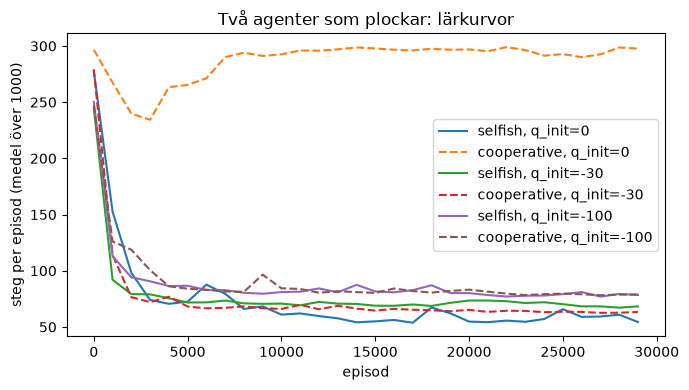

In [27]:
import os
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)
fig, ax = plt.subplots(figsize=(7, 4))
for (q_init, mode), (_, steps_mode) in results2.items():
    means = [np.mean(steps_mode[i:i + 1000]) for i in range(0, len(steps_mode), 1000)]
    ax.plot(range(0, len(steps_mode), 1000), means, label=f"{mode}, q_init={q_init}",
            linestyle="-" if mode == "selfish" else "--")
ax.set_xlabel("episod")
ax.set_ylabel("steg per episod (medel över 1000)")
ax.set_title("Två agenter som plockar: lärkurvor")
ax.legend()
fig.tight_layout()
fig.savefig("figures/two_agent_pickup_learning_curve.png", dpi=150)
plt.show()
